# Binomial Trees with Greeks - Hull Chapter 21 (Questions 21.1-21.5)
Derivatives class - Bloomberg / Greeks activity (Class 4).

**What this notebook does**
1. Builds a Cox-Ross-Rubinstein (CRR) tree for American / European options (stocks and futures).
2. Reads **delta, gamma and theta from a single tree**; estimates **vega and rho by bumping** (they are not in one tree).
3. Validates the engine against Black-Scholes / Black-76 for European options.
4. Solves Hull 21.2 (American put) and 21.4 (American call on corn futures), and applies the control variate (21.3).

## 1. Engine (tree, Greeks, closed-form benchmarks, control variate)

In [1]:
import math


# ----------------------------------------------------------------------------------------------
# Closed-form benchmarks (European)
# ----------------------------------------------------------------------------------------------
def _N(x):
    return 0.5 * (1.0 + math.erf(x / math.sqrt(2.0)))


def black_scholes(S0, K, r, sigma, T, option="put", q=0.0):
    """European option on a stock paying a continuous yield q."""
    d1 = (math.log(S0 / K) + (r - q + 0.5 * sigma ** 2) * T) / (sigma * math.sqrt(T))
    d2 = d1 - sigma * math.sqrt(T)
    if option == "call":
        return S0 * math.exp(-q * T) * _N(d1) - K * math.exp(-r * T) * _N(d2)
    return K * math.exp(-r * T) * _N(-d2) - S0 * math.exp(-q * T) * _N(-d1)


def black_76(F0, K, r, sigma, T, option="call"):
    """European option on a futures price (Black 1976). Same as BS with q = r."""
    return black_scholes(F0, K, r, sigma, T, option, q=r)


# ----------------------------------------------------------------------------------------------
# Binomial tree
# ----------------------------------------------------------------------------------------------
def crr_tree(S0, K, r, sigma, T, N, option="put", american=True, q=0.0, futures=False):
    """
    Build the CRR tree. Node (i, j): i = time step, j = number of up moves.
    Returns a dict with price, parameters and the full stock / option trees.
    """
    if futures:
        q = r  # a futures price has zero drift in the risk-neutral world -> a = e^{(r-q)dt} = 1
    dt = T / N
    u = math.exp(sigma * math.sqrt(dt))
    d = 1.0 / u
    a = math.exp((r - q) * dt)
    p = (a - d) / (u - d)
    disc = math.exp(-r * dt)
    sign = 1.0 if option == "call" else -1.0

    S = [[S0 * u ** j * d ** (i - j) for j in range(i + 1)] for i in range(N + 1)]
    f = [[0.0] * (i + 1) for i in range(N + 1)]
    early = [[False] * (i + 1) for i in range(N + 1)]
    for j in range(N + 1):
        f[N][j] = max(sign * (S[N][j] - K), 0.0)
    for i in range(N - 1, -1, -1):
        for j in range(i + 1):
            hold = disc * (p * f[i + 1][j + 1] + (1.0 - p) * f[i + 1][j])
            if american:
                exercise = max(sign * (S[i][j] - K), 0.0)
                f[i][j] = max(hold, exercise)
                early[i][j] = exercise > hold
            else:
                f[i][j] = hold
    return dict(price=f[0][0], S=S, f=f, early=early, u=u, d=d, a=a, p=p, dt=dt, disc=disc, N=N)


def tree_greeks(tree):
    """Delta, gamma and theta straight from the tree (needs N >= 2)."""
    S, f, dt = tree["S"], tree["f"], tree["dt"]
    delta = (f[1][1] - f[1][0]) / (S[1][1] - S[1][0])
    d_up = (f[2][2] - f[2][1]) / (S[2][2] - S[2][1])
    d_dn = (f[2][1] - f[2][0]) / (S[2][1] - S[2][0])
    gamma = (d_up - d_dn) / (0.5 * (S[2][2] - S[2][0]))
    # S[2][1] = S0 because u*d = 1, so f[2][1] is the option value two steps later at the same price
    theta_year = (f[2][1] - f[0][0]) / (2.0 * dt)
    return dict(delta=delta, gamma=gamma, theta_year=theta_year, theta_day=theta_year / 365.0)


def full_greeks(S0, K, r, sigma, T, N, option="put", american=True, q=0.0, futures=False,
                bump_sigma=0.01, bump_r=0.01):
    """Tree Greeks + vega / rho by bumping (per 1 percentage point of vol / rate)."""
    kw = dict(option=option, american=american, q=q, futures=futures)
    base = crr_tree(S0, K, r, sigma, T, N, **kw)
    g = tree_greeks(base)
    up_vol = crr_tree(S0, K, r, sigma + bump_sigma, T, N, **kw)["price"]
    up_r = crr_tree(S0, K, r + bump_r, sigma, T, N, **kw)["price"]
    g["vega_per_1pct"] = up_vol - base["price"]
    g["rho_per_1pct"] = up_r - base["price"]
    g["price"] = base["price"]
    return g, base


def control_variate(S0, K, r, sigma, T, N, option="put", q=0.0, futures=False):
    """
    Hull Section 21.3 (control variate technique): f_A = f_A(tree) + [f_E(Black-Scholes) - f_E(tree)]
    The European option is priced on the SAME tree and in closed form; the tree's error on the
    European option is assumed to be about the same as its error on the American option.
    """
    f_a_tree = crr_tree(S0, K, r, sigma, T, N, option, True, q, futures)["price"]
    f_e_tree = crr_tree(S0, K, r, sigma, T, N, option, False, q, futures)["price"]
    if futures:
        f_e_exact = black_76(S0, K, r, sigma, T, option)
    else:
        f_e_exact = black_scholes(S0, K, r, sigma, T, option, q)
    return dict(f_a_tree=f_a_tree, f_e_tree=f_e_tree, f_e_exact=f_e_exact,
                f_a_cv=f_a_tree + (f_e_exact - f_e_tree))


def print_tree(tree, label="Stock / option value at each node", decimals=2):
    S, f, early = tree["S"], tree["f"], tree["early"]
    print(label)
    for i in range(tree["N"] + 1):
        cells = []
        for j in range(i, -1, -1):  # highest price first
            mark = "*" if early[i][j] else " "
            cells.append(f"{S[i][j]:.{decimals}f} / {f[i][j]:.{decimals}f}{mark}")
        print(f"  step {i}: " + "   |   ".join(cells))
    print("  (* = early exercise optimal at that node)")




## 2. Question functions

In [2]:
# ----------------------------------------------------------------------------------------------
# Hull Chapter 21 practice questions
# ----------------------------------------------------------------------------------------------
def question_21_2():
    print("=" * 90)
    print("Q21.2  3-month American put, S0=60, K=60, r=10%, sigma=45%, dt = 1 month (N = 3)")
    print("=" * 90)
    S0, K, r, sigma, T, N = 60.0, 60.0, 0.10, 0.45, 0.25, 3
    g, tree = full_greeks(S0, K, r, sigma, T, N, "put", True)
    print(f"u = {tree['u']:.4f}, d = {tree['d']:.4f}, a = {tree['a']:.4f}, p = {tree['p']:.4f}, "
          f"1-p = {1 - tree['p']:.4f}, e^(-r dt) = {tree['disc']:.4f}")
    print_tree(tree)
    print(f"\nAmerican put price (N=3): {g['price']:.4f}")
    print(f"Delta {g['delta']:.4f} | Gamma {g['gamma']:.4f} | Theta {g['theta_year']:.4f}/yr "
          f"({g['theta_day']:.4f}/day) | Vega {g['vega_per_1pct']:.4f} per 1% vol | "
          f"Rho {g['rho_per_1pct']:.4f} per 1% rate")
    cv = control_variate(S0, K, r, sigma, T, N, "put")
    print("\nControl variate (see Q21.3):")
    print(f"  American on tree           {cv['f_a_tree']:.4f}")
    print(f"  European on tree           {cv['f_e_tree']:.4f}")
    print(f"  European Black-Scholes     {cv['f_e_exact']:.4f}")
    print(f"  American, control variate  {cv['f_a_cv']:.4f}")
    print("\nConvergence (American put):")
    for n in (3, 10, 30, 100, 500):
        t = crr_tree(S0, K, r, sigma, T, n, "put", True)["price"]
        print(f"  N = {n:>4}: {t:.4f}")
    return g


def question_21_4():
    print("=" * 90)
    print("Q21.4  9-month American call on corn futures, F0=198, K=200, r=8%, sigma=30%, dt = 3 months")
    print("=" * 90)
    F0, K, r, sigma, T, N = 198.0, 200.0, 0.08, 0.30, 0.75, 3
    g, tree = full_greeks(F0, K, r, sigma, T, N, "call", True, futures=True)
    print(f"u = {tree['u']:.4f}, d = {tree['d']:.4f}, a = {tree['a']:.4f}, p = {tree['p']:.4f}, "
          f"1-p = {1 - tree['p']:.4f}, e^(-r dt) = {tree['disc']:.4f}")
    print_tree(tree, "Futures price / option value at each node (cents)")
    print(f"\nAmerican call on futures price (N=3): {g['price']:.4f} cents")
    print(f"Delta {g['delta']:.4f} | Gamma {g['gamma']:.5f} | Theta {g['theta_year']:.4f}/yr "
          f"({g['theta_day']:.4f}/day) | Vega {g['vega_per_1pct']:.4f} per 1% vol | "
          f"Rho {g['rho_per_1pct']:.4f} per 1% rate")
    cv = control_variate(F0, K, r, sigma, T, N, "call", futures=True)
    print("\nControl variate check:")
    print(f"  European on tree {cv['f_e_tree']:.4f} | European Black-76 {cv['f_e_exact']:.4f} | "
          f"American with control variate {cv['f_a_cv']:.4f}")
    print("\nConvergence (American call on futures):")
    for n in (3, 10, 30, 100, 500):
        t = crr_tree(F0, K, r, sigma, T, n, "call", True, futures=True)["price"]
        print(f"  N = {n:>4}: {t:.4f}")
    return g


def validate_against_black_scholes():
    print("=" * 90)
    print("VALIDATION - European options: binomial tree (N=1000) vs closed form")
    print("=" * 90)
    cases = [
        ("Put  S=60 K=60 r=10% s=45% T=0.25", dict(S0=60, K=60, r=0.10, sigma=0.45, T=0.25, option="put")),
        ("Call S=100 K=105 r=5% s=20% T=1 q=2%", dict(S0=100, K=105, r=0.05, sigma=0.20, T=1.0, option="call", q=0.02)),
        ("Put  S=50 K=52 r=4% s=30% T=0.5", dict(S0=50, K=52, r=0.04, sigma=0.30, T=0.5, option="put")),
    ]
    for label, kw in cases:
        tree = crr_tree(american=False, N=1000, **kw)["price"]
        exact = black_scholes(**kw)
        print(f"  {label:<40} tree {tree:.4f} | BS {exact:.4f} | diff {tree - exact:+.5f}")
    F = dict(F0=198, K=200, r=0.08, sigma=0.30, T=0.75, option="call")
    tree = crr_tree(198, 200, 0.08, 0.30, 0.75, 1000, "call", False, futures=True)["price"]
    print(f"  {'Call on futures F=198 K=200 (Black-76)':<40} tree {tree:.4f} | B76 {black_76(**F):.4f} | "
          f"diff {tree - black_76(**F):+.5f}")


def question_21_1_21_3_21_5():
    print("=" * 90)
    print("Q21.1 / Q21.3 / Q21.5 - conceptual answers are in the written solutions document")
    print("=" * 90)
    print("21.1  One tree gives delta, gamma, theta. Vega and rho need extra trees (bump sigma / r).")
    print("21.3  American = American(tree) + [European(closed form) - European(same tree)].")
    print("21.5  Payoff depends on the average over the path -> not Markov in S alone -> a recombining")
    print("      binomial tree cannot be used directly.")


## 3. Validation: European tree vs closed form

In [3]:
validate_against_black_scholes()

VALIDATION - European options: binomial tree (N=1000) vs closed form
  Put  S=60 K=60 r=10% s=45% T=0.25        tree 4.5986 | BS 4.5999 | diff -0.00133


  Call S=100 K=105 r=5% s=20% T=1 q=2%     tree 6.9867 | BS 6.9869 | diff -0.00017
  Put  S=50 K=52 r=4% s=30% T=0.5          tree 4.7666 | BS 4.7671 | diff -0.00050


  Call on futures F=198 K=200 (Black-76)   tree 18.4473 | B76 18.4430 | diff +0.00430


## 4. Q21.2 - 3-month American put (S0=60, K=60, r=10%, sigma=45%, dt=1 month)

In [4]:
g21_2 = question_21_2()

Q21.2  3-month American put, S0=60, K=60, r=10%, sigma=45%, dt = 1 month (N = 3)
u = 1.1387, d = 0.8782, a = 1.0084, p = 0.4997, 1-p = 0.5003, e^(-r dt) = 0.9917
Stock / option value at each node
  step 0: 60.00 / 5.16 
  step 1: 68.32 / 1.80    |   52.69 / 8.61 
  step 2: 77.80 / 0.00    |   60.00 / 3.63    |   46.27 / 13.73*
  step 3: 88.59 / 0.00    |   68.32 / 0.00    |   52.69 / 7.31    |   40.64 / 19.36 
  (* = early exercise optimal at that node)

American put price (N=3): 5.1628
Delta -0.4356 | Gamma 0.0338 | Theta -9.2175/yr (-0.0253/day) | Vega 0.1274 per 1% vol | Rho -0.0650 per 1% rate

Control variate (see Q21.3):
  American on tree           5.1628
  European on tree           5.0402
  European Black-Scholes     4.5999
  American, control variate  4.7225

Convergence (American put):
  N =    3: 5.1628
  N =   10: 4.6596
  N =   30: 4.7115
  N =  100: 4.7290
  N =  500: 4.7349


### Convergence of Q21.2 as the number of steps grows

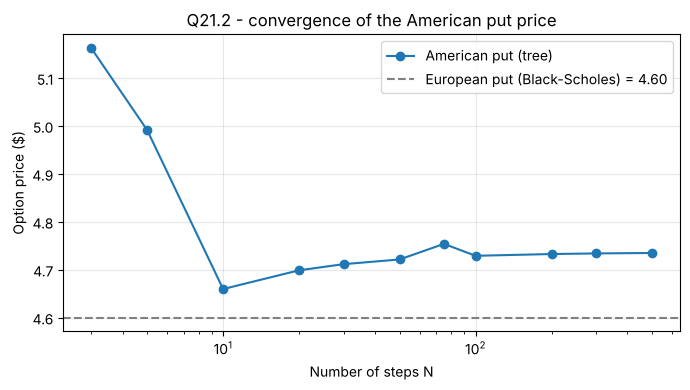

In [5]:
import matplotlib.pyplot as plt
Ns = [3, 5, 10, 20, 30, 50, 75, 100, 200, 300, 500]
am = [crr_tree(60, 60, 0.10, 0.45, 0.25, n, 'put', True)['price'] for n in Ns]
eu_bs = black_scholes(60, 60, 0.10, 0.45, 0.25, 'put')
plt.figure(figsize=(7, 4))
plt.plot(Ns, am, marker='o', label='American put (tree)')
plt.axhline(eu_bs, color='gray', linestyle='--', label=f'European put (Black-Scholes) = {eu_bs:.2f}')
plt.xscale('log'); plt.xlabel('Number of steps N'); plt.ylabel('Option price ($)')
plt.title('Q21.2 - convergence of the American put price'); plt.legend(); plt.grid(alpha=.3)
plt.tight_layout(); plt.show()

## 5. Q21.4 - 9-month American call on corn futures (F0=198, K=200, r=8%, sigma=30%, dt=3 months)

In [6]:
g21_4 = question_21_4()

Q21.4  9-month American call on corn futures, F0=198, K=200, r=8%, sigma=30%, dt = 3 months
u = 1.1618, d = 0.8607, a = 1.0000, p = 0.4626, 1-p = 0.5374, e^(-r dt) = 0.9802
Futures price / option value at each node (cents)
  step 0: 198.00 / 20.34 
  step 1: 230.04 / 37.68    |   170.42 / 6.18 
  step 2: 267.27 / 67.27*   |   198.00 / 13.62    |   146.68 / 0.00 
  step 3: 310.53 / 110.53    |   230.04 / 30.04    |   170.42 / 0.00    |   126.25 / 0.00 
  (* = early exercise optimal at that node)

American call on futures price (N=3): 20.3371 cents
Delta 0.5283 | Gamma 0.00844 | Theta -13.4304/yr (-0.0368/day) | Vega 0.7041 per 1% vol | Rho -0.1176 per 1% rate

Control variate check:
  European on tree 20.0632 | European Black-76 18.4430 | American with control variate 18.7168

Convergence (American call on futures):
  N =    3: 20.3371
  N =   10: 18.4396
  N =   30: 18.6611
  N =  100: 18.7093
  N =  500: 18.7056


## 6. Conceptual questions 21.1, 21.3, 21.5
See the written solutions document for the full explanations.

In [7]:
question_21_1_21_3_21_5()

Q21.1 / Q21.3 / Q21.5 - conceptual answers are in the written solutions document
21.1  One tree gives delta, gamma, theta. Vega and rho need extra trees (bump sigma / r).
21.3  American = American(tree) + [European(closed form) - European(same tree)].
21.5  Payoff depends on the average over the path -> not Markov in S alone -> a recombining
      binomial tree cannot be used directly.
